# Étape 10.3 : une stratégie 130/30

L'étape 10.2 vendait autant qu'elle achetait : le portefeuille perdait l'exposition au marché, qui fait l'essentiel de la performance. Ici, on garde le portefeuille de l'étape 9 (exposé au marché) et on ajoute une petite vente à découvert, limitée aux **très mauvais scores**. Tout le reste est repris de l'étape 9 : mêmes actions, mêmes z-scores, mêmes scores finaux, même zone tampon, même plafond, mêmes frais.

## 1. Données, scores et outils de l'étape 9

In [1]:
import io
import zipfile
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy.optimize import minimize
from scipy.stats import norm
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

warnings.filterwarnings("ignore", category=FutureWarning)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
FIG = ROOT / "docs" / "figures"

pd.set_option("display.precision", 3)
pd.set_option("display.width", 140)

In [2]:
base = pd.read_csv(ROOT / "data" / "processed" / "zscores_sp500_mensuels.csv.gz")
base["mois"] = pd.PeriodIndex(base["mois"], freq="M")
base = base.set_index(["mois", "ticker"]).sort_index()

ajustes = pd.read_csv(RAW / "sp500_cours_ajustes_mensuels.csv", index_col=0)
ajustes.index = pd.PeriodIndex(ajustes.index.astype(str).str[:7], freq="M")
rendements = ajustes.pct_change(fill_method=None)


def lire_bloc_mensuel(chemin_zip):
    with zipfile.ZipFile(chemin_zip) as z:
        texte = z.read(z.namelist()[0]).decode("latin-1")
    lignes = texte.splitlines()
    debut = next(i for i, l in enumerate(lignes) if l.startswith(","))
    bloc = [lignes[debut]]
    for l in lignes[debut + 1:]:
        if not l.strip() or not l.strip()[0].isdigit():
            break
        bloc.append(l)
    df = pd.read_csv(io.StringIO("\n".join(bloc)), index_col=0)
    df.columns = df.columns.str.strip()
    df.index = pd.PeriodIndex(df.index.astype(str), freq="M")
    return df.astype(float) / 100


facteurs = lire_bloc_mensuel(RAW / "F-F_Research_Data_5_Factors_2x3_CSV.zip").join(
    lire_bloc_mensuel(RAW / "F-F_Momentum_Factor_CSV.zip"), how="inner")
rf = facteurs["RF"]

etf = pd.read_csv(RAW / "cours_mensuels.csv", index_col=0)[["SPY", "RSP"]]
etf.index = pd.PeriodIndex(etf.index, freq="M")
rend_etf = etf.pct_change()

mois = base.index.get_level_values("mois").unique()
print(f"z-scores : {mois[0]} à {mois[-1]}, {len(mois)} mois")

z-scores : 2012-02 à 2026-08, 175 mois


In [3]:
STYLES = {"z_smb": "SMB", "z_hml": "HML", "z_rmw": "RMW", "z_cma": "CMA", "z_mom": "Mom"}
Z = base[list(STYLES)]

In [4]:
def poids_erc(cov):
    # Spinu (2013) : le minimum de 1/2 y'Σy - (1/n) Σ log(y) donne des contributions au risque égales.
    n = len(cov)
    y0 = 1 / np.sqrt(np.diag(cov))
    y = minimize(lambda y: 0.5 * y @ cov @ y - np.log(y).sum() / n, y0,
                 jac=lambda y: cov @ y - 1 / (n * y), bounds=[(1e-10, None)] * n, method="L-BFGS-B").x
    return y / y.sum()


def contributions(w, cov):
    rc = w * (cov @ w)
    return rc / rc.sum()


poids = {}
for m in mois:
    histo = facteurs.loc[:m, list(STYLES.values())].iloc[-60:]
    poids[m] = poids_erc(histo.cov().values)
poids = pd.DataFrame(poids, index=list(STYLES.values())).T

# Contrôle : contributions au risque au dernier mois
cov_fin = facteurs.loc[:mois[-1], list(STYLES.values())].iloc[-60:].cov().values
print("Contributions au risque (dernier mois) :", np.round(contributions(poids.iloc[-1].values, cov_fin), 3))
print("\nPoids ERC des facteurs dans le score, résumé sur la période :")
poids.describe().loc[["mean", "min", "max"]].round(2)

Contributions au risque (dernier mois) : [0.2 0.2 0.2 0.2 0.2]

Poids ERC des facteurs dans le score, résumé sur la période :


,SMB,HML,RMW,CMA,Mom
mean,0.23,0.13,0.30,0.18,0.17
min,0.17,0.08,0.25,0.12,0.08
max,0.32,0.22,0.36,0.23,0.22


In [5]:
def score_final(w):
    # w : DataFrame (mois x facteurs) de poids
    wl = w.reindex(Z.index.get_level_values("mois")).set_axis(Z.index)
    wl.columns = list(STYLES)
    s = (Z.fillna(0) * wl).sum(axis=1)[Z.notna().sum(axis=1) >= 3]
    return s.groupby(level="mois").transform(lambda x: (x - x.mean()) / x.std())


egal = pd.DataFrame(0.2, index=mois, columns=list(STYLES.values()))
scores = pd.DataFrame({"score_equipondere": score_final(egal), "score_erc": score_final(poids)})
print(f"{len(scores):,}".replace(",", " "), "scores (mois, action)")
print(f"Corrélation entre les deux scores : {scores.corr().iloc[0, 1]:.2f}")
scores.to_csv(ROOT / "data" / "processed" / "scores_finaux_sp500.csv.gz", float_format="%.5g")

72 741 scores (mois, action)
Corrélation entre les deux scores : 0.92


In [6]:
capi = base["capitalisation"]
PLAFOND = 0.10


def plafonner(w, plafond=PLAFOND):
    # Aucune action au-dessus du plafond ; l'excédent est redistribué aux autres, au prorata.
    w = w / w.sum()
    while (w > plafond + 1e-12).any():
        trop = w > plafond
        excedent = (w[trop] - plafond).sum()
        w[trop] = plafond
        w[~trop] += excedent * w[~trop] / w[~trop].sum()
    return w


def poids_cibles(score, seuil=0.30, tampon=0.40, ponderation="capi_score"):
    cibles, tenus = {}, set()
    for m in mois[:-1]:
        s = score.xs(m).dropna()
        c = capi.xs(m).reindex(s.index).dropna()
        s = s[c.index]
        rang = s.rank(ascending=False, pct=True)
        selection = set(rang[rang <= seuil].index)
        if tampon:
            selection |= set(rang[rang <= tampon].index) & tenus
        selection = sorted(selection)
        tenus = set(selection)
        if ponderation == "egale":
            w = pd.Series(1.0, index=selection)
        elif ponderation == "capi":
            w = c[selection]
        else:
            w = c[selection] * (1 + s[selection]).clip(lower=0)
        cibles[m] = plafonner(w)
    return cibles

In [7]:
def backtest(cibles, frais=0.0010):
    lignes, derive, manquants = {}, pd.Series(dtype=float), 0
    for m, w in cibles.items():
        rotation = w.subtract(derive, fill_value=0).abs().sum()
        r = rendements.loc[m + 1].reindex(w.index)
        manquants += int(r.isna().sum())
        r = r.fillna(0)
        brut = float((w * r).sum())
        lignes[m + 1] = {"brut": brut, "rotation": rotation, "net": brut - frais * rotation}
        derive = w * (1 + r)
        derive = derive / derive.sum()
    sortie = pd.DataFrame(lignes).T
    sortie.attrs["manquants"] = manquants
    return sortie


def univers_capi():
    return {m: capi.xs(m).dropna() / capi.xs(m).dropna().sum() for m in mois[:-1]}

In [8]:
def test_moyenne(a):
    m = sm.OLS(a.values, np.ones(len(a))).fit(cov_type="HAC", cov_kwds={"maxlags": 6})
    return m.params[0], m.tvalues[0], m.pvalues[0]


def indices_bootstrap(n, bloc_moyen, rng):
    idx = np.empty(n, dtype=int)
    idx[0] = rng.integers(n)
    for i in range(1, n):
        idx[i] = rng.integers(n) if rng.random() < 1 / bloc_moyen else (idx[i - 1] + 1) % n
    return idx


def sharpe(x, r_f):
    e = x - r_f
    return e.mean() / e.std() * np.sqrt(12)


def bootstrap(strat, bench, n_tirages=5000, bloc_moyen=6, graine=0):
    rng = np.random.default_rng(graine)
    s, b, f = strat.values, bench.values, rf.reindex(strat.index).values
    actif, d_sharpe = [], []
    for _ in range(n_tirages):
        i = indices_bootstrap(len(s), bloc_moyen, rng)
        actif.append((s[i] - b[i]).mean() * 12)
        d_sharpe.append(sharpe(s[i], f[i]) - sharpe(b[i], f[i]))
    return np.percentile(actif, [2.5, 97.5]), np.percentile(d_sharpe, [2.5, 97.5])

## 2. Le portefeuille 130/30

Pour 100 $ de capital, chaque fin de mois $t$ :

- **130 $ achetés** : le portefeuille de l'étape 9. Les 30 % meilleurs scores (gardés tant qu'ils restent dans les 40 % meilleurs), poids $\propto \text{capitalisation} \times (1 + S)$, plafond de 10 % de la jambe.
- **30 $ vendus à découvert** : seulement les 10 % plus mauvais scores (gardés tant qu'ils restent dans les 15 % plus mauvais), poids $\propto \text{capitalisation} \times (1 - S)$, plafond de 10 % de la jambe.
- Exposition nette : 130 − 30 = 100 %, comme le long-only. Exposition brute : 160 %.

**Financement** : l'argent de la vente à découvert reste chez le courtier, qui prête en échange les 30 $ achetés en plus (montage courant chez les courtiers pour les 130/30). Il ne reste donc pas de liquidités, et on paie :
- le coût d'emprunt des titres vendus : 0,25 % par an sur les 30 $ (D'Avolio, 2002) ;
- l'écart entre le taux payé sur le prêt et le taux reçu sur l'argent bloqué : 0,50 % par an sur les 30 $.

Rendement mensuel :

$$r_{t+1} = 1{,}3 \, r^{\text{achetées}}_{t+1} - 0{,}3 \, r^{\text{vendues}}_{t+1} - \text{frais} - 0{,}3 \times \frac{0{,}25 \% + 0{,}50 \%}{12}$$

Chaque mois, on revient à 130 / 30 : la rotation compte les échanges sur les deux jambes, en dollars par dollar de capital. Frais de 0,10 % par dollar échangé, comme à l'étape 9.

In [9]:
EMPRUNT, FINANCEMENT = 0.0025, 0.0050


def selection_jambe(s, rang, seuil, tampon, tenus):
    choix = set(rang[rang <= seuil].index) | (set(rang[rang <= tampon].index) & tenus)
    return sorted(choix)


def poids_130_30(score, seuil_achat=0.30, tampon_achat=0.40, seuil_vente=0.10, tampon_vente=0.15):
    jambes, tenus = {}, {"achat": set(), "vente": set()}
    for m in mois[:-1]:
        s = score.xs(m).dropna()
        c = capi.xs(m).reindex(s.index).dropna()
        s = s[c.index]
        achat = selection_jambe(s, s.rank(ascending=False, pct=True), seuil_achat, tampon_achat, tenus["achat"])
        vente = selection_jambe(s, s.rank(ascending=True, pct=True), seuil_vente, tampon_vente, tenus["vente"])
        tenus = {"achat": set(achat), "vente": set(vente)}
        jambes[m] = {"achat": plafonner(c[achat] * (1 + s[achat]).clip(lower=0)),
                     "vente": plafonner(c[vente] * (1 - s[vente]).clip(lower=0))}
    return jambes


def backtest_130_30(jambes, levier=0.30, frais=0.0010, emprunt=EMPRUNT, financement=FINANCEMENT):
    taille = {"achat": 1 + levier, "vente": levier}
    lignes = {}
    derive = {"achat": pd.Series(dtype=float), "vente": pd.Series(dtype=float)}
    for m, j in jambes.items():
        # rotation en dollars par dollar de capital, sur les deux jambes
        rotation = sum((taille[n] * w).subtract(derive[n], fill_value=0).abs().sum() for n, w in j.items())
        r = {n: rendements.loc[m + 1].reindex(w.index).fillna(0) for n, w in j.items()}
        r_jambe = {n: float((w * r[n]).sum()) for n, w in j.items()}
        brut = taille["achat"] * r_jambe["achat"] - taille["vente"] * r_jambe["vente"]
        net = brut - frais * rotation - levier * (emprunt + financement) / 12
        for n, w in j.items():
            derive[n] = taille[n] * w * (1 + r[n]) / (1 + brut)
        lignes[m + 1] = {"achetées": r_jambe["achat"], "vendues": r_jambe["vente"], "brut": brut,
                         "rotation": rotation, "net": net}
    return pd.DataFrame(lignes).T


cent30 = {"équipondéré": poids_130_30(scores["score_equipondere"]),
          "ERC": poids_130_30(scores["score_erc"])}
strat_130_30 = {f"130/30 {k}": backtest_130_30(v) for k, v in cent30.items()}
long_only = {"Long-only équipondéré (étape 9)": backtest(poids_cibles(scores["score_equipondere"])),
             "Long-only ERC (étape 9)": backtest(poids_cibles(scores["score_erc"]))}
univers = backtest(univers_capi())
periode = univers.index

for k, v in cent30.items():
    n_a = np.mean([len(x["achat"]) for x in v.values()])
    n_v = np.mean([len(x["vente"]) for x in v.values()])
    print(f"{k} : {n_a:.0f} actions achetées et {n_v:.0f} vendues en moyenne")
print(f"Période : {periode[0]} à {periode[-1]}, {len(periode)} mois")

équipondéré : 141 actions achetées et 49 vendues en moyenne
ERC : 142 actions achetées et 49 vendues en moyenne
Période : 2012-03 à 2026-08, 174 mois


## 3. Résultats

In [10]:
def indicateurs(r):
    r = r.reindex(periode)
    exces = r - rf.reindex(periode)
    valeur = (1 + r).cumprod()
    return pd.Series({
        "rendement annuel": valeur.iloc[-1] ** (12 / len(r)) - 1,
        "volatilité": r.std() * np.sqrt(12),
        "Sharpe": exces.mean() / exces.std() * np.sqrt(12),
        "perte maximale": (valeur / valeur.cummax() - 1).min(),
    })


series = {k: v["net"] for k, v in long_only.items()}
series.update({k: v["net"] for k, v in strat_130_30.items()})
series["Univers (capitalisation)"] = univers["net"]
series["SPY"] = rend_etf["SPY"]
resultats = pd.DataFrame({k: indicateurs(v) for k, v in series.items()}).T
toutes = {**long_only, **strat_130_30}
resultats["rotation annuelle"] = [toutes[k]["rotation"].iloc[1:].mean() * 12 if k in toutes else np.nan
                                  for k in resultats.index]
resultats.style.format({"rendement annuel": "{:.1%}", "volatilité": "{:.1%}", "Sharpe": "{:.2f}",
                        "perte maximale": "{:.1%}", "rotation annuelle": "{:.0%}"}, na_rep="")

,rendement annuel,volatilité,Sharpe,perte maximale,rotation annuelle
Long-only équipondéré (étape 9),15.6%,15.8%,0.90,-28.2%,315%
Long-only ERC (étape 9),14.7%,15.4%,0.87,-23.2%,278%
130/30 équipondéré,14.9%,17.5%,0.80,-32.2%,472%
130/30 ERC,13.6%,16.7%,0.75,-25.5%,416%
Univers (capitalisation),15.1%,14.0%,0.96,-23.6%,
SPY,14.6%,14.0%,0.93,-23.9%,


### La vente à découvert ajoute-t-elle quelque chose ?

Le 130/30 est comparé au long-only de l'étape 9 (même score) et à l'univers pondéré par la capitalisation. Mêmes outils qu'à l'étape 9 : $t$ de Newey-West et bootstrap par blocs.

In [11]:
lignes = []
for score in ["équipondéré", "ERC"]:
    nom = f"130/30 {score}"
    for nom_bench, bench in [(f"Long-only {score} (étape 9)", long_only[f"Long-only {score} (étape 9)"]["net"]),
                             ("Univers (capitalisation)", univers["net"])]:
        s = strat_130_30[nom]["net"]
        a = s - bench
        moy, t, p = test_moyenne(a)
        ic_actif, ic_sharpe = bootstrap(s, bench)
        lignes.append({"stratégie": nom, "comparé à": nom_bench, "rendement actif annuel": 12 * moy,
                       "écart de suivi": a.std() * np.sqrt(12), "t (Newey-West)": t, "p-valeur": p,
                       "IC 95 % rendement actif": f"[{ic_actif[0]:+.1%} ; {ic_actif[1]:+.1%}]",
                       "écart de Sharpe": sharpe(s, rf.reindex(periode)) - sharpe(bench, rf.reindex(periode)),
                       "IC 95 % écart de Sharpe": f"[{ic_sharpe[0]:+.2f} ; {ic_sharpe[1]:+.2f}]"})
pd.DataFrame(lignes).set_index(["stratégie", "comparé à"]).style.format(
    {"rendement actif annuel": "{:+.2%}", "écart de suivi": "{:.1%}", "t (Newey-West)": "{:+.2f}",
     "p-valeur": "{:.2f}", "écart de Sharpe": "{:+.2f}"})

In [12]:
# Ce que rapporte la jambe vendue : les 10 % plus mauvais scores face au marché et à la jambe achetée (brut, annuel)
pd.DataFrame({k: {"actions achetées": 12 * v["achetées"].mean(), "actions vendues": 12 * v["vendues"].mean(),
                  "univers": 12 * univers["brut"].mean(),
                  "gain de la vente (0,3 × (univers − vendues))": 0.3 * 12 * (univers["brut"] - v["vendues"]).mean()}
              for k, v in strat_130_30.items()}).T.style.format("{:+.2%}")

,actions achetées,actions vendues,univers,"gain de la vente (0,3 × (univers − vendues))"
130/30 équipondéré,+16.18%,+15.97%,+15.10%,-0.26%
130/30 ERC,+15.25%,+16.67%,+15.10%,-0.47%


### Expositions aux six facteurs

Régression de l'excédent net sur les facteurs de Fama et French, comme à l'étape 9.

In [13]:
SIX = ["Mkt-RF", "SMB", "HML", "RMW", "CMA", "Mom"]
X = sm.add_constant(facteurs.loc[periode, SIX])
expo = {}
for nom, r in series.items():
    if nom in toutes:
        m = sm.OLS(r.reindex(periode) - rf.reindex(periode), X).fit(cov_type="HAC", cov_kwds={"maxlags": 6})
        ligne = m.params.rename({"const": "alpha annuel"})
        ligne["alpha annuel"] *= 12
        ligne["t alpha"] = m.tvalues["const"]
        ligne["R²"] = m.rsquared
        expo[nom] = ligne
expositions = pd.DataFrame(expo).T
expositions.style.format("{:.2f}").format("{:+.1%}", subset=["alpha annuel"])

,alpha annuel,Mkt-RF,SMB,HML,RMW,CMA,Mom,t alpha,R²
Long-only équipondéré (étape 9),+0.4%,1.03,0.09,0.39,-0.00,0.15,0.16,0.35,0.93
Long-only ERC (étape 9),-0.7%,1.04,0.11,0.21,0.03,0.19,0.20,-0.53,0.91
130/30 équipondéré,-0.2%,1.04,0.21,0.56,-0.02,0.25,0.25,-0.10,0.88
130/30 ERC,-1.7%,1.04,0.22,0.32,0.04,0.30,0.29,-0.87,0.84


### Robustesse : sous-périodes, frais, part vendue

In [14]:
lignes = {}
for score in ["équipondéré", "ERC"]:
    a_tout = strat_130_30[f"130/30 {score}"]["net"] - long_only[f"Long-only {score} (étape 9)"]["net"]
    for sp, (d, f) in {"2012-2019": ("2012-03", "2019-12"), "2020-2026": ("2020-01", "2026-08")}.items():
        a = a_tout.loc[d:f]
        moy, t, _ = test_moyenne(a)
        lignes[(f"130/30 {score}", sp)] = {"écart annuel avec le long-only": 12 * moy, "t (Newey-West)": t}
pd.DataFrame(lignes).T.style.format({"écart annuel avec le long-only": "{:+.2%}", "t (Newey-West)": "{:+.2f}"})

In [15]:
# Écart annuel avec le long-only selon les frais de transaction et le coût total de la vente à découvert
lignes = {}
for frais_pb in [0, 10, 25]:
    for cout in [0.0, 0.0075, 0.02]:
        ligne = {}
        for score in ["équipondéré", "ERC"]:
            bt, lo = strat_130_30[f"130/30 {score}"], long_only[f"Long-only {score} (étape 9)"]
            net = bt["brut"] - frais_pb / 1e4 * bt["rotation"] - 0.3 * cout / 12
            ligne[f"130/30 {score}"] = 12 * (net - (lo["brut"] - frais_pb / 1e4 * lo["rotation"])).mean()
        lignes[(f"{frais_pb} pb", f"{cout:.2%}")] = ligne
pd.DataFrame(lignes).T.rename_axis(["frais par dollar échangé", "emprunt + financement (par an)"]).style.format("{:+.2%}")

In [16]:
# Autres règles de vente (score équipondéré) : part des pires scores vendue et taille de la jambe vendue
lignes = {}
lo = long_only["Long-only équipondéré (étape 9)"]["net"]
for seuil, tampon in [(0.05, 0.075), (0.10, 0.15), (0.20, 0.30), (0.30, 0.40)]:
    jambes = poids_130_30(scores["score_equipondere"], seuil_vente=seuil, tampon_vente=tampon)
    for levier in [0.20, 0.30, 0.50]:
        a = backtest_130_30(jambes, levier=levier)["net"] - lo
        moy, t, _ = test_moyenne(a)
        lignes[(f"{seuil:.0%} pires", f"{100 + 100 * levier:.0f}/{100 * levier:.0f}")] = {
            "écart annuel avec le long-only": 12 * moy, "t (Newey-West)": t}
variantes = pd.DataFrame(lignes).T.rename_axis(["actions vendues", "montage"])
variantes.style.format({"écart annuel avec le long-only": "{:+.2%}", "t (Newey-West)": "{:+.2f}"})

## 4. Graphique

In [17]:
SURFACE, TEXTE, TEXTE2, GRILLE = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLEU, ORANGE, AQUA, JAUNE, MAGENTA, VERT = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"
GRIS = "#8d8c88"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "DejaVu Sans", "font.size": 10,
    "text.color": TEXTE, "axes.labelcolor": TEXTE2, "xtick.color": TEXTE2, "ytick.color": TEXTE2,
    "axes.edgecolor": GRILLE, "axes.grid": True, "grid.color": GRILLE, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False,
})


def sauver(fig, nom):
    fig.savefig(FIG / nom, dpi=200, bbox_inches="tight")


def virgule(fmt):
    return plt.FuncFormatter(lambda v, _: fmt.format(v).replace(".", ",").replace("-", "−"))


COULEURS = {"Score équipondéré": BLEU, "Score ERC": ORANGE, "Univers (capitalisation)": TEXTE2, "SPY": GRIS}

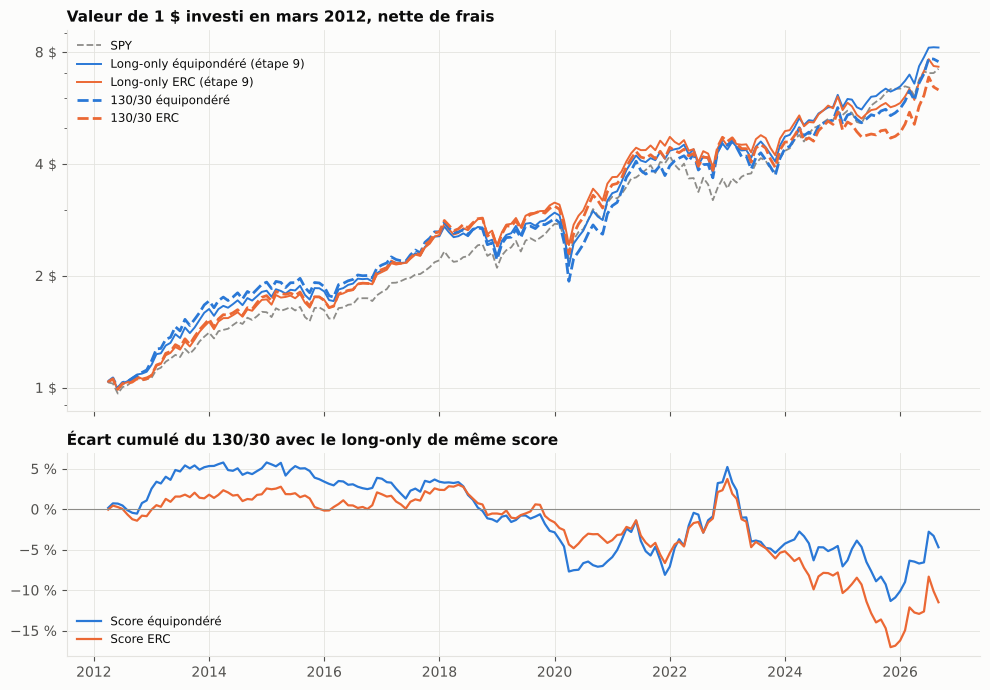

In [18]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1.6]})
d = periode.to_timestamp(how="end")
traces = [("SPY", GRIS, "--", 1.3), ("Long-only équipondéré (étape 9)", BLEU, "-", 1.4),
          ("Long-only ERC (étape 9)", ORANGE, "-", 1.4),
          ("130/30 équipondéré", BLEU, (0, (4, 1.5)), 2.0), ("130/30 ERC", ORANGE, (0, (4, 1.5)), 2.0)]
for nom, couleur, style, lw in traces:
    v = (1 + series[nom].reindex(periode)).cumprod()
    ax1.plot(d, v, color=couleur, ls=style, lw=lw, label=nom)
for score, couleur in [("équipondéré", BLEU), ("ERC", ORANGE)]:
    a = strat_130_30[f"130/30 {score}"]["net"] - long_only[f"Long-only {score} (étape 9)"]["net"]
    ax2.plot(d, 100 * a.reindex(periode).cumsum(), color=couleur, lw=1.6, label=f"Score {score}")
ax2.axhline(0, color=GRIS, lw=0.8)
ax1.set_yscale("log")
ax1.set_yticks([1, 2, 4, 8])
ax1.yaxis.set_major_formatter(virgule("{:.0f} $"))
ax1.yaxis.set_minor_formatter(plt.NullFormatter())
ax1.set_title("Valeur de 1 $ investi en mars 2012, nette de frais")
ax1.legend(loc="upper left", fontsize=8.5)
ax2.yaxis.set_major_formatter(virgule("{:.0f} %"))
ax2.set_title("Écart cumulé du 130/30 avec le long-only de même score")
ax2.legend(loc="lower left", fontsize=8.5)
ax2.xaxis.set_major_locator(mdates.YearLocator(2))
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.tight_layout()
sauver(fig, "strategie_130_30.png")
plt.show()